# ЛАБОРАТОРНА РОБОТА № 4

## Візуальний аналіз даних та часові ряди — аналіз у двох середовищах

**Курс:** СК26 «Інтелектуальний аналіз та візуалізація даних»
**Кафедра систем штучного інтелекту, Національний університет «Львівська політехніка»**
**Оцінювання:** 4 бали
Студентка групи ШІ-31, Андрусишин Соломія

---

## Визначення варіанта

Заповніть три поля в клітинці нижче й виконайте обидві службові клітинки —
номер варіанта, ринок і товар визначаться автоматично.

In [ ]:
SURNAME_NAME = 'Андрусишин Соломія'     
GROUP        = 'ШІ-31'    
NUMBER       = 1     
assert SURNAME_NAME.strip(), 'Впишіть прізвище та ім\'я'
assert GROUP.strip(),        'Впишіть групу'
assert isinstance(NUMBER, int) and 1 <= NUMBER <= 30, 'Номер має бути цілим від 1 до 30'
print('Дані прийнято:', SURNAME_NAME, '|', GROUP, '| номер', NUMBER)

Дані прийнято: Андрусишин Соломія | ШІ-31 | номер 1


In [4]:
import json

VARIANTS = json.load(open('lr4_variants_student (1).json', encoding='utf-8'))
V = VARIANTS[NUMBER - 1]

MARKET, GOOD, GOOD_UA = V['ринок'], V['товар'], V['товар_укр']

print('=' * 72)
print(f'ВАРІАНТ {V["варіант"]}   ·   {SURNAME_NAME}   ·   {GROUP}')
print('=' * 72)
print()
print(f'   Ринок:  {MARKET}')
print(f'   Товар:  {GOOD_UA}   (у наборі даних: {GOOD})')
print()
print('Далі в роботі користуйтеся змінними MARKET і GOOD —')
print('тоді весь код автоматично працюватиме саме з вашим рядом.')
print()
print('Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців')
print('Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)')

ВАРІАНТ 1   ·   Андрусишин Соломія   ·   ШІ-31

   Ринок:  Odesa
   Товар:  хліб пшеничний   (у наборі даних: Bread (wheat) - Retail)

Далі в роботі користуйтеся змінними MARKET і GOOD —
тоді весь код автоматично працюватиме саме з вашим рядом.

Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців
Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)


> ⚠️ Якщо ці дві клітинки не виконано, усі подальші завдання не мають сенсу:
> перевіряти роботу будуть **за вашим варіантом**, а не за тим рядом, який ви оберете самі.

| | |
|---|---|
| **Дата здачі** |29.10.2026|
| **Підпис** |Андрусишин|

---
## Мета роботи

Виконати повний цикл аналізу одного часового ряду **у двох середовищах** — у Python та в Orange —
і пояснити, чому однаково названі метрики в них дають різні числа.

## Вихідні дані

| Файл | Зміст |
|---|---|
| `ціни_україна_2014_2017.csv` | Роздрібні ціни на 25 товарів по 28 ринках України, щомісяця, 03.2014 – 12.2017 |
| `lr4_variants_student.json` | Розподіл варіантів (зчитується автоматично) |
| `ЛР4_помилковий_аналіз.ipynb` | Звіт колеги, який треба відрецензувати (завдання 8) |

Це той самий набір, з яким ми працювали на лекції 4. **Національне середнє в завданнях не використовується** —
ваш ряд це конкретний обласний ринок.

## Що здавати

1. **`ЛР4_Прізвище_Варіант.ipynb`** — цей зошит із вашим кодом, графіками та письмовими висновками.
2. **`ряд_для_orange.csv`** — експортований ряд (завдання 9).
3. **`потік_orange.ows`** — збережений потік Orange.
4. **Знімки екрана** з Orange для завдань 10–13 — вставте їх у зошит або додайте окремими файлами.

## Правила

* **Код пишете самостійно** — у цьому зошиті навмисно немає заготовок.
* **Користуватися штучним інтелектом дозволено**, але ви зобов'язані заповнити декларацію в кінці зошита.
* **Кожне число має супроводжуватися висновком словами.** Робота, у якій є графіки й таблиці,
  але немає письмових відповідей на поставлені питання, оцінюється як невиконана.
* Усі обчислення мають бути **відтворюваними**: зошит має виконуватися від початку до кінця
  командою *Restart & Run All* без помилок.

---
# ЧАСТИНА 1. Аналіз засобами Python

*Виконується аудиторно.*

## Завдання 1. Підготовка ряду

Витягніть із набору ряд свого варіанта — скористайтеся змінними `MARKET` і `GOOD`,
які визначилися у службовій клітинці, — і приведіть його до **повної місячної сітки**
з березня 2014 по грудень 2017.

**У звіті наведіть:**
1. скільки місяців у сітці та скільки з них мають вимір;
2. у якому саме місяці пропуск;
3. **чому** цей пропуск виник — і чи він у вашому ряді один.

> 💡 **Підказка.** Пропуск є в усіх без винятку рядах набору. Якщо ви знайшли більше одного — перевірте, чи правильно побудована сітка.

In [ ]:

import pandas as pd

df = pd.read_csv("ціни_україна_2014_2017 (1).csv")

df["date"] = pd.to_datetime(
    dict(year=df["рік"], month=df["місяць"], day=1)
)

filtered = df[
    (df["ринок"] == MARKET) &
    (df["товар"] == GOOD)
]

s = filtered.set_index("date")["ціна"].sort_index()

months = pd.date_range("2014-03-01", "2017-12-01", freq="MS")

s = s.reindex(months)

print("Усього місяців:", len(s))
print("Місяців із даними:", s.notna().sum())
print("Пропущених місяців:", s.isna().sum())
print("Місяць пропуску:", s[s.isna()].index.strftime("%m.%Y").tolist())


Усього місяців: 46
Місяців із даними: 45
Пропущених місяців: 1
Місяць пропуску: ['08.2017']


**Висновок до завдання 1:**

У результаті підготовки часового ряду було відібрано дані про роздрібні ціни на пшеничний хліб на ринку Одеси за період із березня 2014 року до грудня 2017 року.
Повний часовий ряд містить 46 місяців, із яких 45 мають фактичні значення цін. Виявлено один пропуск — серпень 2017 року.
Пропуск пов'язаний із відсутністю відповідного спостереження у вихідному наборі даних. Для забезпечення рівномірного місячного інтервалу було створено повну часову сітку. 

## Завдання 2. Заповнення пропуску

Заповніть пропуск. Порівняйте **щонайменше три** способи: перенесення останнього значення,
лінійну інтерполяцію та ще один на ваш вибір.

**У звіті наведіть:**
1. значення, яке дає кожен спосіб;
2. який спосіб ви обрали і **чому саме його**;
3. за якої умови заповнювати пропуск було б **неприпустимо** — наведіть приклад із цього ж набору даних.

> 💡 **Підказка.** Третій пункт стосується не вашого ряду, а принципу. Згадайте, які області зникають із набору у 2014 році.

In [ ]:
s_ffill = s.ffill()

s_linear = s.interpolate(method="linear")

neighbors = s.loc[
    ["2017-06-01", "2017-07-01",
     "2017-09-01", "2017-10-01"]
]

s_median = s.copy()
s_median.loc["2017-08-01"] = neighbors.median()

date = "2017-08-01"

print("Перенесення останнього значення:", s_ffill.loc[date])
print("Лінійна інтерполяція:", s_linear.loc[date])
print("Медіана сусідніх:", s_median.loc[date])

s_filled = s_linear.copy()

print("Залишилося пропусків:", s_filled.isna().sum())


Перенесення останнього значення: 9.46
Лінійна інтерполяція: 9.46
Медіана сусідніх: 9.545000000000002
Залишилося пропусків: 0


**Висновок до завдання 2:**

Для подальшого аналізу обрано лінійну інтерполяцію, оскільки вона враховує значення з обох боків пропуску та передбачає рівномірну зміну між ними. У нашому випадку ціни за липень і вересень однакові, тому результат збігається з методом перенесення останнього значення.

Приклад неприпустимого заповнення: у вихідному наборі даних для ринку Crimea спостереження є лише за березень 2014 року, а для m. Sevastopol — за березень і квітень 2014 року. Подальша відсутність даних збігається з окупацією Криму. Автоматичне перенесення останньої відомої ціни на наступні роки створило б штучні дані, які не відображають фактичних ринкових умов.

## Завдання 3. Візуальна розвідка

Побудуйте **не менше трьох** графіків свого ряду, які відповідають на різні питання.

**У звіті наведіть:**
1. для кожного графіка — яке питання він ставить і **чому обрано саме таку геометрію та шкалу**;
2. одну знахідку, якої ви не очікували до побудови графіків.

> 💡 **Підказка.** Графік без пояснення вибору форми не зараховується. Нагадування з лекції: геометрія — це твердження про дані.

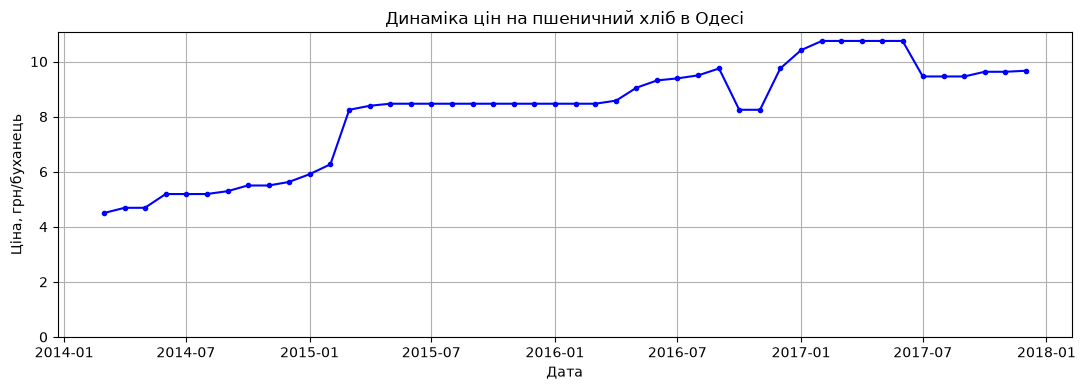

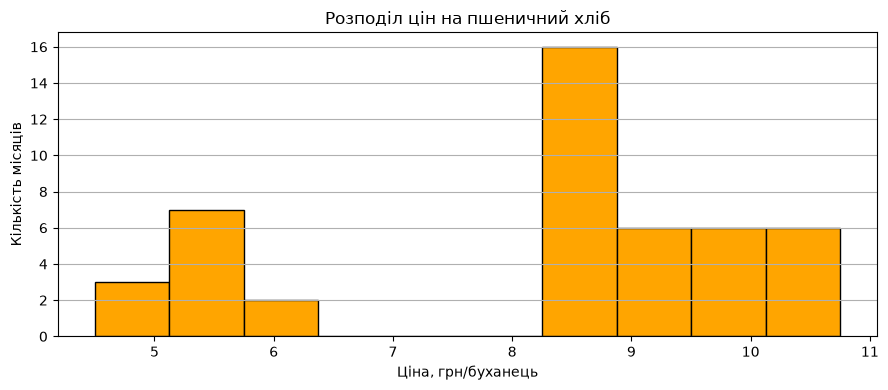

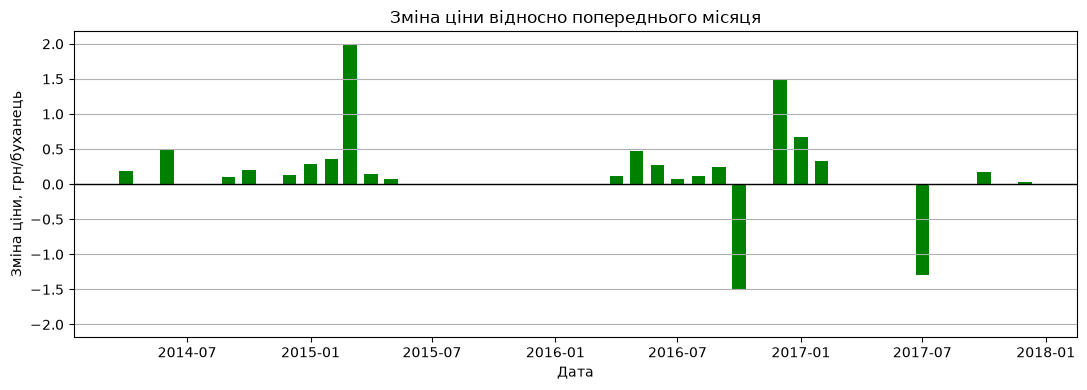

In [ ]:

import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.figure(figsize=(11, 4))

plt.plot(s_filled.index, s_filled.values,
         marker="o", markersize=3, color="blue")

plt.title("Динаміка цін на пшеничний хліб в Одесі")
plt.xlabel("Дата")
plt.ylabel("Ціна, грн/буханець")
plt.ylim(bottom=0)
plt.grid(True)
plt.tight_layout()
plt.show()


plt.figure(figsize=(9, 4))

plt.hist(s_filled, bins=10,
         color="orange", edgecolor="black")

plt.title("Розподіл цін на пшеничний хліб")
plt.xlabel("Ціна, грн/буханець")
plt.ylabel("Кількість місяців")
plt.ylim(bottom=0)
plt.grid(axis="y")
plt.tight_layout()
plt.show()

changes = s_filled.diff().dropna()

plt.figure(figsize=(11, 4))

plt.bar(changes.index, changes.values,
        width=20, color="green")

plt.axhline(0, color="black", linewidth=1)

plt.title("Зміна ціни відносно попереднього місяця")
plt.xlabel("Дата")
plt.ylabel("Зміна ціни, грн/буханець")

limit = max(abs(changes.min()), abs(changes.max())) * 1.1
plt.ylim(-limit, limit)

plt.grid(axis="y")
plt.tight_layout()
plt.show()


**Висновок до завдання 3:**

Було побудовано три графіки. Лінійний показує зміну цін у часі, гістограма — найчастіші значення, а стовпчиковий — місячні зростання та падіння. Для всіх графіків використано лінійну шкалу, оскільки вона дозволяє правильно порівнювати значення.

Загалом ціна зросла з 4,50 до 9,67 грн. Найбільше мене здивувало те, що протягом 11 місяців ціна взагалі не змінювалася і становила 8,47 грн.

## Завдання 4. Розкладання на складові

Розкладіть ряд на тренд, сезонну складову та залишок методом STL із періодом 12.

**У звіті наведіть:**
1. чотирипанельний графік розкладання;
2. числові значення сили сезонності $F_S$ та сили тренду $F_T$;
3. **висновок: чи є у вашому ряді сезонність**, із посиланням на порогове значення.

> 💡 **Підказка.** STL поверне сезонну складову завжди. Ваше завдання — вирішити, чи вона означає щось, а не чи вона є.

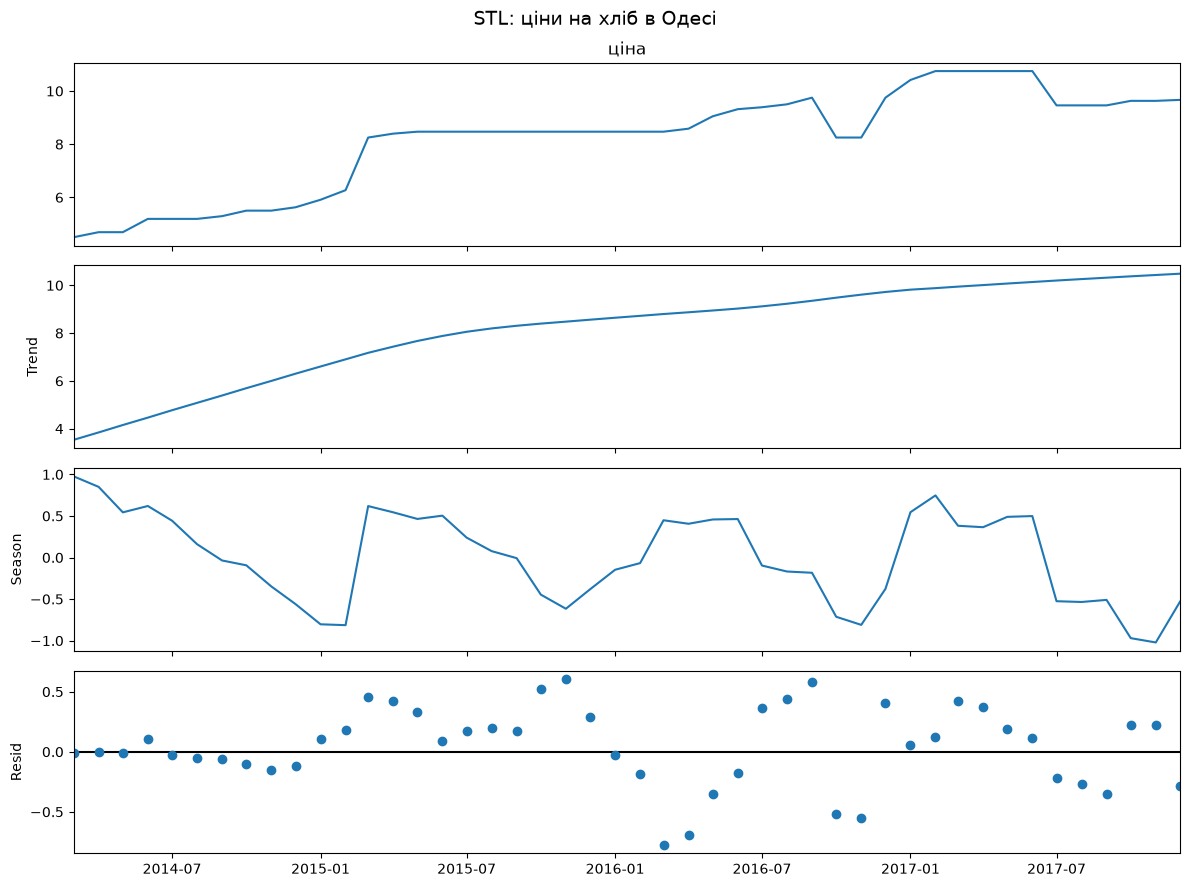

Сила сезонності Fs = 0.740
Сила тренду Ft = 0.974
Висновок: сезонність присутня


In [12]:
from statsmodels.tsa.seasonal import STL
import numpy as np
import matplotlib.pyplot as plt

stl = STL(s_filled, period=12)
result = stl.fit()

fig = result.plot()
fig.set_size_inches(12, 9)
fig.suptitle("STL: ціни на хліб в Одесі", fontsize=14)
plt.tight_layout()
plt.show()

Fs = max(0, 1 - np.var(result.resid) /
         np.var(result.seasonal + result.resid))


Ft = max(0, 1 - np.var(result.resid) /
         np.var(result.trend + result.resid))

print(f"Сила сезонності Fs = {Fs:.3f}")
print(f"Сила тренду Ft = {Ft:.3f}")

if Fs < 0.3:
    print("Висновок: вираженої сезонності немає")
else:
    print("Висновок: сезонність присутня")


**Висновок до завдання 4:**

Методом STL я розклала часовий ряд на тренд, сезонність і залишок. Отримала силу тренду Ft = 0,974 та силу сезонності Fs = 0,740. Оскільки Fs більше за порогове значення 0,3, сезонність у ряді присутня. Водночас тренд сильніший і показує загальне зростання цін на хліб.

## Завдання 5. Стаціонарність

Побудуйте ACF і PACF вихідного ряду та його першої різниці. Застосуйте тести ADF і KPSS до обох.

**У звіті наведіть:**
1. графіки ACF і PACF до та після диференціювання;
2. таблицю з $p$-значеннями обох тестів для обох рядів;
3. висновок про стаціонарність **із зазначенням, узгоджуються тести між собою чи ні**;
4. якщо не узгоджуються — ваше пояснення, чому.

> 💡 **Підказка.** Нульові гіпотези ADF і KPSS протилежні. Перш ніж писати висновок, перевірте, що ви не переплутали напрямок.

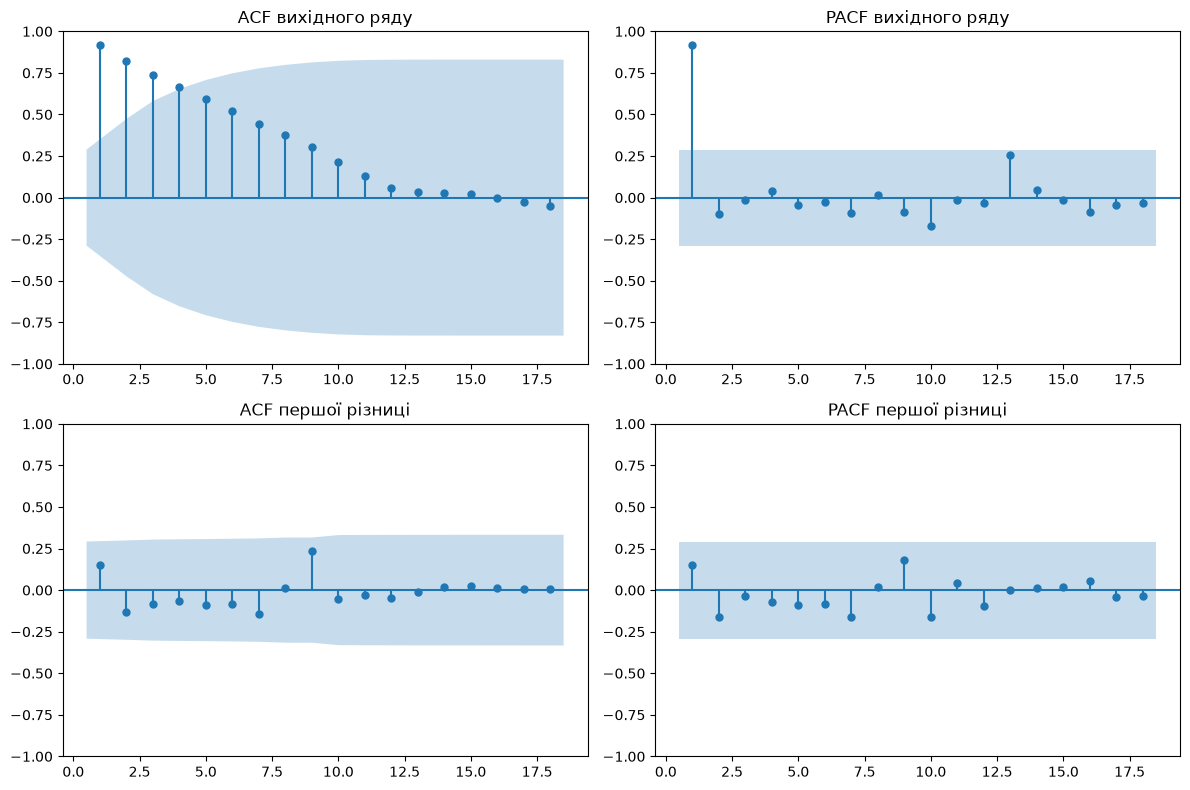

          Ряд  ADF p-value  KPSS p-value
 Вихідний ряд     0.364121          0.01
Перша різниця     0.000002          0.10


C:\Users\Соломія\AppData\Local\Temp\ipykernel_24940\678762012.py:34: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_p = adfuller(series, autolag="AIC")[1]
C:\Users\Соломія\AppData\Local\Temp\ipykernel_24940\678762012.py:35: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_p = kpss(series, regression="c", nlags="auto")[1]
C:\Users\Соломія\AppData\Local\Temp\ipykernel_24940\678762012.py:35: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 

In [13]:

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, kpss
import pandas as pd
import matplotlib.pyplot as plt

s_diff = s_filled.diff().dropna()

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

plot_acf(s_filled, lags=18, ax=axes[0, 0], zero=False)
axes[0, 0].set_title("ACF вихідного ряду")

plot_pacf(s_filled, lags=18, ax=axes[0, 1],
          method="ywm", zero=False)
axes[0, 1].set_title("PACF вихідного ряду")

plot_acf(s_diff, lags=18, ax=axes[1, 0], zero=False)
axes[1, 0].set_title("ACF першої різниці")

plot_pacf(s_diff, lags=18, ax=axes[1, 1],
          method="ywm", zero=False)
axes[1, 1].set_title("PACF першої різниці")

plt.tight_layout()
plt.show()


results = []

for name, series in [
    ("Вихідний ряд", s_filled),
    ("Перша різниця", s_diff)
]:
    adf_p = adfuller(series, autolag="AIC")[1]
    kpss_p = kpss(series, regression="c", nlags="auto")[1]

    results.append({
        "Ряд": name,
        "ADF p-value": adf_p,
        "KPSS p-value": kpss_p
    })

test_results = pd.DataFrame(results)

print(test_results.to_string(index=False))


**Висновок до завдання 5:**

Побудувала графіки ACF і PACF до та після диференціювання. Тести ADF (p = 0,364) і KPSS (p = 0,01) показали, що початковий ряд нестаціонарний. Після першої різниці він став стаціонарним: ADF p < 0,05, KPSS p = 0,10. Обидва тести узгоджуються, а на графіках ACF і PACF після диференціювання більшість значень перебувають у довірчих межах.

## Завдання 6. Базисні прогнози та ретроспективна перевірка

Побудуйте **чотири** базисні прогнози: наївний, сезонний наївний, середнє та дрейф.
Оцініть їх **ретроспективною перевіркою з рухомим початком**: **7 фолдів по 3 кроки**,
навчальна частина розширюється.

**У звіті наведіть:**
1. таблицю MAE, RMSE і MAPE для всіх чотирьох базисів;
2. який базис виявився найкращим і **чому саме він** — поясніть через властивості вашого ряду;
3. для порівняння: ту саму оцінку, зроблену звичайним випадковим поділом 75/25, і **у скільки разів** вона відрізняється.

> 💡 **Підказка.** Кількість фолдів і кроків задана жорстко — у Частині 2 вона має збігтися з налаштуваннями Orange.

In [14]:

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

def forecast_baseline(train, method, h=3):
    values = train.to_numpy()

    if method == "Наївний":
        return np.repeat(values[-1], h)

    if method == "Сезонний наївний":
        return np.resize(values[-12:], h)

    if method == "Середнє":
        return np.repeat(values.mean(), h)

    if method == "Дрейф":
        slope = (values[-1] - values[0]) / (len(values) - 1)
        return values[-1] + slope * np.arange(1, h + 1)


def calculate_metrics(actual, predicted):
    actual = np.asarray(actual)
    error = actual - predicted

    mae = np.mean(np.abs(error))
    rmse = np.sqrt(np.mean(error ** 2))
    mape = np.mean(np.abs(error / actual)) * 100

    return mae, rmse, mape


methods = ["Наївний", "Сезонний наївний",
           "Середнє", "Дрейф"]

rows = []

for f in range(7, 0, -1):
    n_train = len(s_filled) - 3 * f

    train = s_filled.iloc[:n_train]
    test = s_filled.iloc[n_train:n_train + 3]

    for method in methods:
        predicted = forecast_baseline(train, method)
        mae, rmse, mape = calculate_metrics(test.values, predicted)

        rows.append([method, f, mae, rmse, mape])

scores = pd.DataFrame(
    rows, columns=["Метод", "Фолд", "MAE", "RMSE", "MAPE (%)"]
)

rolling_results = scores.groupby("Метод", sort=False)[
    ["MAE", "RMSE", "MAPE (%)"]
].mean()

print("Результати ретроспективної перевірки:")
print(rolling_results.round(3))

print("\nНайкращий метод за MAE:",
      rolling_results["MAE"].idxmin())


train_idx, test_idx = train_test_split(
    np.arange(len(s_filled)),
    test_size=0.25,
    random_state=42,
    shuffle=True
)

train_random = s_filled.iloc[np.sort(train_idx)]
test_random = s_filled.iloc[np.sort(test_idx)]

random_scores = []

for method in methods:
    predicted = forecast_baseline(
        train_random, method, h=len(test_random)
    )

    mae, rmse, mape = calculate_metrics(
        test_random.values, predicted
    )

    random_scores.append([method, mae, rmse, mape])

random_results = pd.DataFrame(
    random_scores,
    columns=["Метод", "MAE", "RMSE", "MAPE (%)"]
).set_index("Метод")

print("Випадковий поділ 75/25:")
print(random_results.round(3))

ratio = random_results / rolling_results

print("\nВідношення помилок (випадковий / рухомий):")
print(ratio.round(2))



Результати ретроспективної перевірки:
                    MAE   RMSE  MAPE (%)
Метод                                   
Наївний           0.586  0.639     6.282
Сезонний наївний  1.029  1.103    10.193
Середнє           2.137  2.166    21.685
Дрейф             0.616  0.646     6.610

Найкращий метод за MAE: Наївний
Випадковий поділ 75/25:
                    MAE   RMSE  MAPE (%)
Метод                                   
Наївний           2.018  2.645    33.696
Сезонний наївний  2.161  2.546    33.612
Середнє           1.731  2.076    26.063
Дрейф             2.675  3.112    42.161

Відношення помилок (випадковий / рухомий):
                   MAE  RMSE  MAPE (%)
Метод                                 
Наївний           3.44  4.14      5.36
Сезонний наївний  2.10  2.31      3.30
Середнє           0.81  0.96      1.20
Дрейф             4.34  4.82      6.38


**Висновок до завдання 6:**

Я порівняла чотири методи прогнозування на 7 фолдах по 3 місяці. Найкращим виявився наївний метод (MAE = 0,586, RMSE = 0,639, MAPE = 6,282%), оскільки ціни часто залишалися стабільними. При випадковому поділі 75/25 його MAE стала більшою у 3,44 раза. Такий поділ не підходить для часових рядів, бо порушує порядок дат і може використовувати майбутні дані для прогнозування минулого.

## Завдання 7. Модель ARIMA

Побудуйте модель ARIMA і оцініть її **на тих самих 7 фолдах по 3 кроки**.

Обов'язково використайте порядок **(1, 1, 1)** — саме його ви відтворюватимете в Orange.
Додатково визначте, який порядок $(p, d, q)$ ви обрали б **за виглядом ACF і PACF** із завдання 5.

**У звіті наведіть:**
1. MAE, RMSE і MAPE моделі ARIMA(1,1,1) на рухомому початку;
2. обґрунтування порядку, який ви обрали б самостійно, з посиланням на конкретні лаги;
3. **порівняння з найкращим базисом із завдання 6** — і прямий висновок, чи має ця модель право на існування;
4. графік залишків моделі та висновок, чи лишилася в них структура.

> 💡 **Підказка.** Якщо ARIMA програла базису — це законний результат, а не помилка. Напишіть про це прямо.

c:\Users\Соломія\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\Соломія\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


Результати ARIMA(1,1,1):
MAE         0.589
RMSE        0.634
MAPE (%)    6.330
dtype: float64

Порівняння моделей:
                MAE   RMSE  MAPE (%)
Наївний       0.586  0.639     6.282
ARIMA(1,1,1)  0.589  0.634     6.330


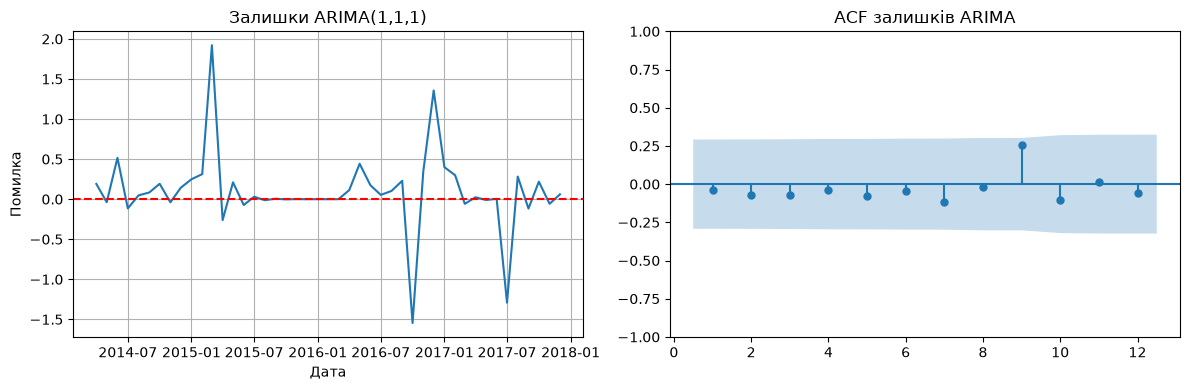

Ljung-Box p-value: 0.8793


In [16]:

from statsmodels.tsa.arima.model import ARIMA
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox

arima_scores = []

for f in range(7, 0, -1):
    n_train = len(s_filled) - 3 * f

    train = s_filled.iloc[:n_train]
    test = s_filled.iloc[n_train:n_train + 3]

    model = ARIMA(train, order=(1, 1, 1))
    fitted = model.fit()

    predicted = fitted.forecast(steps=3)

    mae, rmse, mape = calculate_metrics(
        test.values, predicted.values
    )

    arima_scores.append([f, mae, rmse, mape])

arima_df = pd.DataFrame(
    arima_scores,
    columns=["Фолд", "MAE", "RMSE", "MAPE (%)"]
)

arima_result = arima_df[
    ["MAE", "RMSE", "MAPE (%)"]
].mean()

print("Результати ARIMA(1,1,1):")
print(arima_result.round(3))

comparison = pd.DataFrame({
    "Наївний": rolling_results.loc["Наївний"],
    "ARIMA(1,1,1)": arima_result
}).T

print("\nПорівняння моделей:")
print(comparison.round(3))


model_full = ARIMA(s_filled, order=(1, 1, 1)).fit()

residuals = model_full.resid.iloc[1:]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(residuals.index, residuals.values)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_title("Залишки ARIMA(1,1,1)")
axes[0].set_xlabel("Дата")
axes[0].set_ylabel("Помилка")
axes[0].grid(True)

plot_acf(residuals, lags=12, ax=axes[1], zero=False)
axes[1].set_title("ACF залишків ARIMA")

plt.tight_layout()
plt.show()

lb = acorr_ljungbox(residuals, lags=[12], return_df=True)

print("Ljung-Box p-value:",
      round(lb["lb_pvalue"].iloc[0], 4))



**Висновок до завдання 7:**

Побудувала модель ARIMA(1,1,1). Отримала MAE = 0,589, RMSE = 0,634 та MAPE = 6,330%. Порівняно з наївним методом суттєвого покращення немає, тому для цього ряду простий прогноз не гірший.
За графіками ACF і PACF я б також спробувала ARIMA(0,1,0), оскільки після першої різниці значущих лагів майже немає.
На графіку залишків є кілька різких відхилень, але значущої автокореляції не виявлено (Ljung–Box p = 0,8793). Отже, модель загалом прибрала часову залежність, але не перевершила простий базис.

## Завдання 8. Точка зміни режиму

Знайдіть у своєму ряді точку, після якої змінюється **рівень** ряду.
Скористайтеся скануванням: для кожної кандидатної дати порівняйте середні до і після
та оберіть дату з найбільшою t-статистикою.

**У звіті наведіть:**
1. графік ряду з позначеною знайденою датою;
2. дату, значення t-статистики, середні рівні до і після;
3. **чи є ця точка значущою** — і якщо ні, так і напишіть;
4. чим знайдена точка відрізняється від звичайного сезонного сплеску у вашому ряді.

> 💡 **Підказка.** Не плутайте зсув рівня з сезонним піком. Якщо «аномалії» повторюються щороку в ті самі місяці — це сезон.

Дата зміни: 03.2015
t-статистика: 18.641
p-value: 4.76728e-19
Скориговане p-value: 1.09647e-17
Середня ціна до: 5.296 грн
Середня ціна після: 9.210 грн
Різниця середніх статистично значуща за тестом


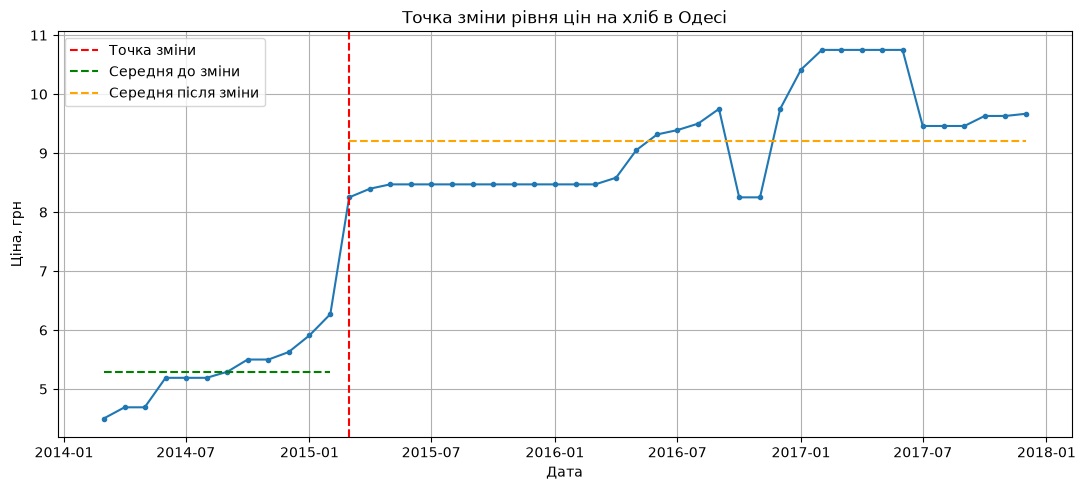

In [ ]:

from scipy.stats import ttest_ind
import matplotlib.pyplot as plt
import numpy as np

candidates = []

for k in range(12, len(s_filled) - 12 + 1):

    before = s_filled.iloc[:k]
    after = s_filled.iloc[k:]

    t, p = ttest_ind(before, after, equal_var=False)

    candidates.append((k, abs(t), p))

best_k, best_t, best_p = max(
    candidates, key=lambda x: x[1]
)

change_date = s_filled.index[best_k]

mean_before = s_filled.iloc[:best_k].mean()
mean_after = s_filled.iloc[best_k:].mean()

p_adjusted = min(best_p * len(candidates), 1)

print("Дата зміни:", change_date.strftime("%m.%Y"))
print(f"t-статистика: {best_t:.3f}")
print(f"p-value: {best_p:.6g}")
print(f"Скориговане p-value: {p_adjusted:.6g}")
print(f"Середня ціна до: {mean_before:.3f} грн")
print(f"Середня ціна після: {mean_after:.3f} грн")

if p_adjusted < 0.05:
    print("Різниця середніх статистично значуща за тестом")
else:
    print("Статистичну значущість не підтверджено")


plt.figure(figsize=(11, 5))

plt.plot(s_filled.index, s_filled.values,
         marker="o", markersize=3)

plt.axvline(change_date, color="red",
            linestyle="--", label="Точка зміни")

plt.hlines(mean_before,
           s_filled.index[0],
           s_filled.index[best_k - 1],
           colors="green", linestyles="--",
           label="Середня до зміни")

plt.hlines(mean_after,
           s_filled.index[best_k],
           s_filled.index[-1],
           colors="orange", linestyles="--",
           label="Середня після зміни")

plt.title("Точка зміни рівня цін на хліб в Одесі")
plt.xlabel("Дата")
plt.ylabel("Ціна, грн")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


**Висновок до завдання 8:**

Знайшла точку зміни рівня цін у березні 2015 року (t = 18,641). Середня ціна до неї становила 5,296 грн, а після — 9,210 грн. За тестом зміна статистично значуща (p < 0,05), хоча на результат міг вплинути загальний тренд. Це не звичайний сезонний пік, оскільки ціни перейшли на вищий рівень і залишалися там тривалий час, а не поверталися до попереднього щороку.

## Завдання 9. Рецензія на чужий аналіз

Відкрийте `ЛР4_помилковий_аналіз.ipynb`. Це звіт, зроблений на іншому ряді з того самого набору.
Він виконується без помилок і виглядає переконливо, але містить **методологічні помилки**.

**У звіті наведіть:**
1. перелік знайдених помилок — для кожної вкажіть номер клітинки, суть помилки й **чим вона небезпечна**;
2. для трьох найсерйозніших — як саме їх виправити.

> 💡 **Підказка.** Помилок щонайменше вісім. Шукайте не синтаксис, а порушення принципів роботи з часовими рядами.

In [19]:
print("""
Знайдені методологічні помилки:

1. Клітинка 4. Перевірено лише NaN, але не відсутні місяці.
   Через це пропущено серпень 2017 року і ряд помилково
   вважається повним.

2. Клітинка 6. Зі зростання ціни на гречку зроблено висновок
   про падіння купівельної спроможності. Але для такого
   висновку потрібно врахувати також доходи населення.

3. Клітинка 8. Порівнюються MAE гречки та яловичини.
   Через різні рівні цін таке порівняння некоректне.
   Краще використовувати відносні метрики.

4. Клітинка 10. Висока кореляція між цінами у двох областях
   трактується як причинний зв'язок. Насправді обидві
   ціни можуть змінюватися через спільні фактори.

5. Клітинка 12. Висновок про сезонність зроблено лише
   за результатом STL. Потрібно обчислити Fs
   і порівняти його з порогом 0,3.

6. Клітинка 14. Неправильно пояснено тест ADF.
   При p = 0,233 немає підстав відхиляти
   гіпотезу про нестаціонарність.

7. Клітинка 14. Ряд диференціювали двічі без
   достатнього обґрунтування. Це може призвести
   до втрати корисної інформації.

8. Клітинка 16. Аномалії шукають у вихідних цінах,
   а не в залишках. Також у тексті вказано поріг
   2 стандартні відхилення, а в коді використано 1,3.

9. Клітинка 18. Використано випадковий поділ 75/25.
   Це порушує хронологію часового ряду і може
   призвести до використання майбутніх даних.

10. Клітинка 18. Перед обчисленням MAE ціни сортуються
    за величиною, а не за датою. Через це прогнози
    порівнюються з неправильними значеннями.

11. Клітинка 18. ARIMA і сезонний наївний метод
    оцінюються на різних даних. Тому їхні
    результати не можна коректно порівнювати.

12. Клітинка 22. Вісь Y стовпчикового графіка
    не починається з нуля, що візуально
    перебільшує зміну цін.


Виправлення трьох найсерйозніших помилок:

1. Клітинка 4.
   Створити повну місячну сітку через reindex(),
   знайти пропуски та заповнити їх обґрунтованим
   методом, наприклад лінійною інтерполяцією.

2. Клітинка 14.
   Правильно інтерпретувати ADF, додатково
   провести KPSS і перевірити першу різницю.
   Не диференціювати ряд двічі без потреби.

3. Клітинка 18.
   Замість випадкового поділу застосувати
   ретроспективну перевірку: 7 фолдів по
   3 місяці. Порівнювати моделі на тих самих
   датах і не сортувати ціни за величиною.
""")



Знайдені методологічні помилки:

1. Клітинка 4. Перевірено лише NaN, але не відсутні місяці.
   Через це пропущено серпень 2017 року і ряд помилково
   вважається повним.

2. Клітинка 6. Зі зростання ціни на гречку зроблено висновок
   про падіння купівельної спроможності. Але для такого
   висновку потрібно врахувати також доходи населення.

3. Клітинка 8. Порівнюються MAE гречки та яловичини.
   Через різні рівні цін таке порівняння некоректне.
   Краще використовувати відносні метрики.

4. Клітинка 10. Висока кореляція між цінами у двох областях
   трактується як причинний зв'язок. Насправді обидві
   ціни можуть змінюватися через спільні фактори.

5. Клітинка 12. Висновок про сезонність зроблено лише
   за результатом STL. Потрібно обчислити Fs
   і порівняти його з порогом 0,3.

6. Клітинка 14. Неправильно пояснено тест ADF.
   При p = 0,233 немає підстав відхиляти
   гіпотезу про нестаціонарність.

7. Клітинка 14. Ряд диференціювали двічі без
   достатнього обґрунтування. Це мож

**Висновок до завдання 9:**

хоча код виконується без помилок, деякі результати неправильно інтерпретовані, а оцінювання прогнозів проведене некоректно. Тому висновки такого аналізу не можна вважати повністю надійними.

## Завдання 10. Експорт ряду для Orange

Збережіть підготовлений ряд у файл `ряд_для_orange.csv` **рівно у такому вигляді**:

| Стовпець | Тип | Зміст |
|---|---|---|
| `date` | текст у форматі `РРРР-ММ-ДД` | перше число місяця |
| `price` | число | ціна, пропуск уже заповнений |

Один рядок на місяць, 46 рядків плюс заголовок, роздільник — кома, кодування UTF-8.

**У звіті наведіть:**
1. підтвердження, що файл має 46 рядків даних і не містить порожніх значень.

> 💡 **Підказка.** Формат заданий жорстко: Orange має отримати **точно ті самі** дані, що й Python, інакше порівняння в Частині 2 втрачає сенс.

In [20]:
import pandas as pd

orange_df = pd.DataFrame({
    "date": s_filled.index.strftime("%Y-%m-%d"),
    "price": s_filled.values
})

orange_df.to_csv(
    "ряд_для_orange.csv",
    index=False,
    sep=",",
    encoding="utf-8"
)

check = pd.read_csv("ряд_для_orange.csv")

print("Кількість рядків:", len(check))
print("Кількість пропусків:", check.isna().sum().sum())
print("Назви стовпців:", check.columns.tolist())

print("\nПерші 5 рядків:")
print(check.head())

print("\nОстанні 5 рядків:")
print(check.tail())

assert len(check) == 46
assert check.isna().sum().sum() == 0
assert check.columns.tolist() == ["date", "price"]

print("\nФайл успішно створено!")


Кількість рядків: 46
Кількість пропусків: 0
Назви стовпців: ['date', 'price']

Перші 5 рядків:
         date  price
0  2014-03-01   4.50
1  2014-04-01   4.69
2  2014-05-01   4.69
3  2014-06-01   5.19
4  2014-07-01   5.19

Останні 5 рядків:
          date   price
41  2017-08-01  9.4600
42  2017-09-01  9.4600
43  2017-10-01  9.6300
44  2017-11-01  9.6300
45  2017-12-01  9.6667

Файл успішно створено!


**Висновок до завдання 10:**

Підготовлений часовий ряд збережено у файл ряд_для_orange.csv. Файл містить 46 рядків і два стовпці: date та price. Пропущених значень немає, формат дат відповідає вимогам Orange.

---
# ЧАСТИНА 2. Той самий аналіз засобами Orange

*Виконується самостійно.*

Потрібен додаток **Timeseries**: у Orange відкрийте *Options → Add-ons…* і встановіть `Orange3-Timeseries`.

**Головна умова цієї частини:** Orange має отримати **ті самі дані** й **ті самі налаштування перевірки**,
що й Python у Частині 1. Тоді будь-яка розбіжність у числах пояснюється **лише означеннями метрик**,
а не різними даними чи різними моделями. Саме це вам і треба довести.

## Завдання 11. Потік опрацювання даних

Побудуйте в Orange потік:

`File` → `As Timeseries` → `Interpolate` → `Line Chart`

У віджеті **File** завантажте свій `ряд_для_orange.csv`; переконайтеся, що `date` розпізнано
як **time**, а `price` — як **numeric**. У віджеті **As Timeseries** оберіть `date` як часову змінну.

**У звіті наведіть:**
1. знімок екрана з побудованим потоком;
2. знімок `Line Chart` із вашим рядом;
3. підтвердження, що графік у Orange збігається з графіком із завдання 3.

> 💡 **Підказка.** Якщо `date` розпізнано як текст, поверніться до завдання 10 і перевірте формат дати.

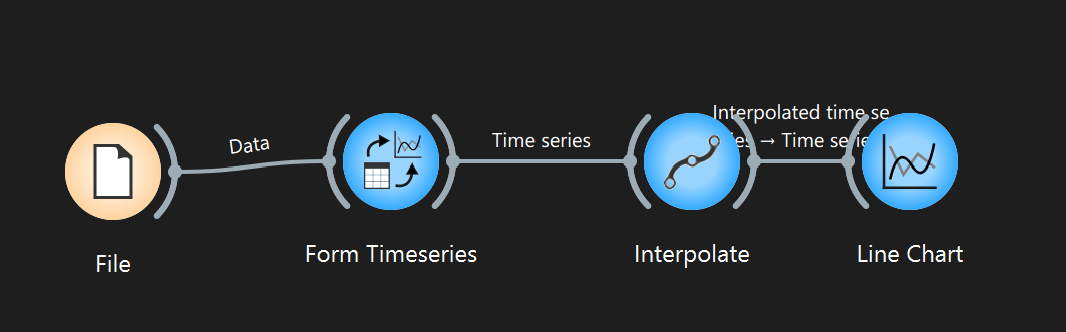

Рис. 1. Побудований потік обробки даних в Orange: File → Form Timeseries → Interpolate → Line Chart.

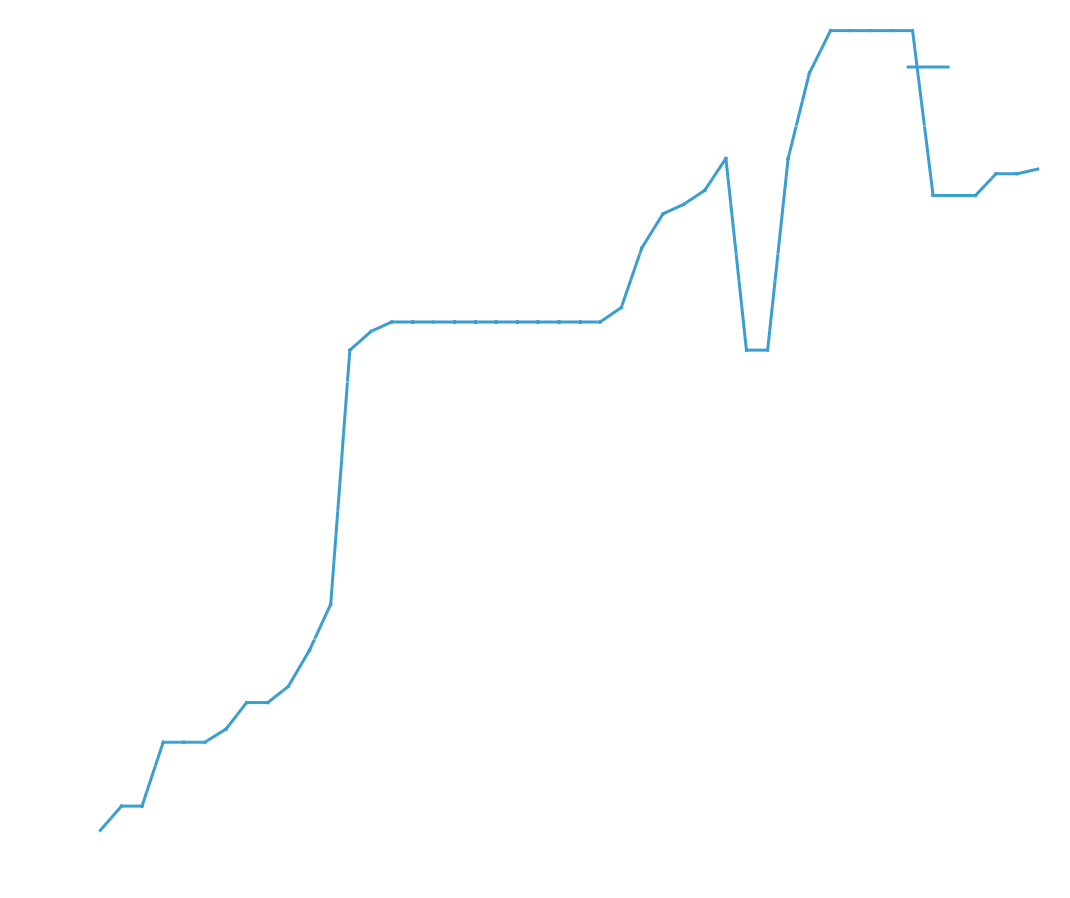

Рис. 2. Графік зміни цін на пшеничний хліб в Одесі за 2014–2017 роки, побудований в Orange.

Кількість значень: 46
Ціни збігаються: True


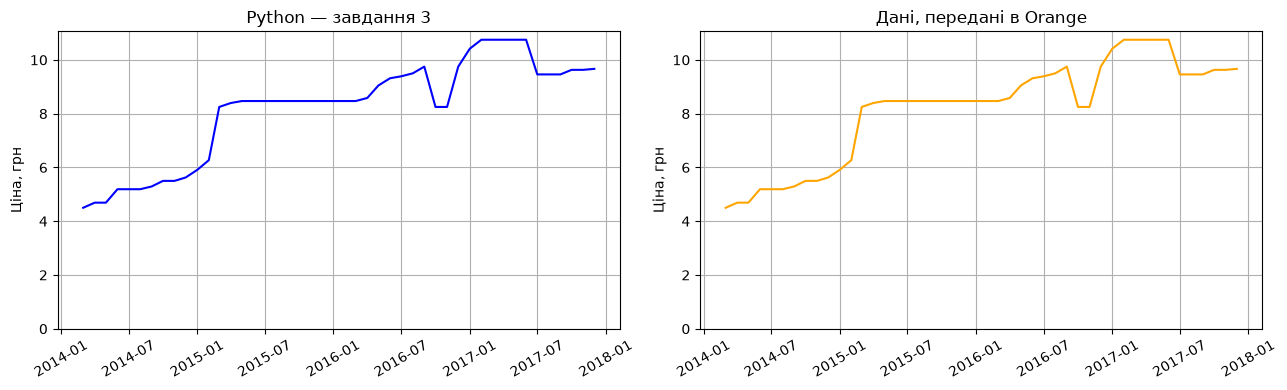

In [22]:
import pandas as pd
import matplotlib.pyplot as plt

orange_data = pd.read_csv("ряд_для_orange.csv")
orange_data["date"] = pd.to_datetime(orange_data["date"])

python_prices = s_filled.values
orange_prices = orange_data["price"].values

import numpy as np

print("Кількість значень:", len(orange_prices))
print("Ціни збігаються:", np.allclose(python_prices, orange_prices))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(s_filled.index, s_filled.values, color="blue")
axes[0].set_title("Python — завдання 3")
axes[0].set_ylabel("Ціна, грн")
axes[0].grid(True)

axes[1].plot(orange_data["date"], orange_data["price"], color="orange")
axes[1].set_title("Дані, передані в Orange")
axes[1].set_ylabel("Ціна, грн")
axes[1].grid(True)

for ax in axes:
    ax.tick_params(axis="x", rotation=30)
    ax.set_ylim(bottom=0)

plt.tight_layout()
plt.show()

**Висновок до завдання 11:**

В Orange побудувала потік із чотирьох блоків і отримала графік цін. Він збігається з графіком у Python, тому дані завантажені та оброблені правильно.

## Завдання 12. Автокореляція та диференціювання

Додайте до потоку віджети `Correlogram`, `Difference` та `Seasonal Adjustment`.

**У звіті наведіть:**
1. знімок корелограми;
2. зіставлення з ACF із завдання 5: **чи збігаються висновки** про значущі лаги;
3. знімок сезонно скоригованого ряду та порівняння з сезонною складовою STL із завдання 4.

> 💡 **Підказка.** Orange і statsmodels рахують автокореляцію однаково — якщо картина різна, перевірте, чи однакові дані на вході.

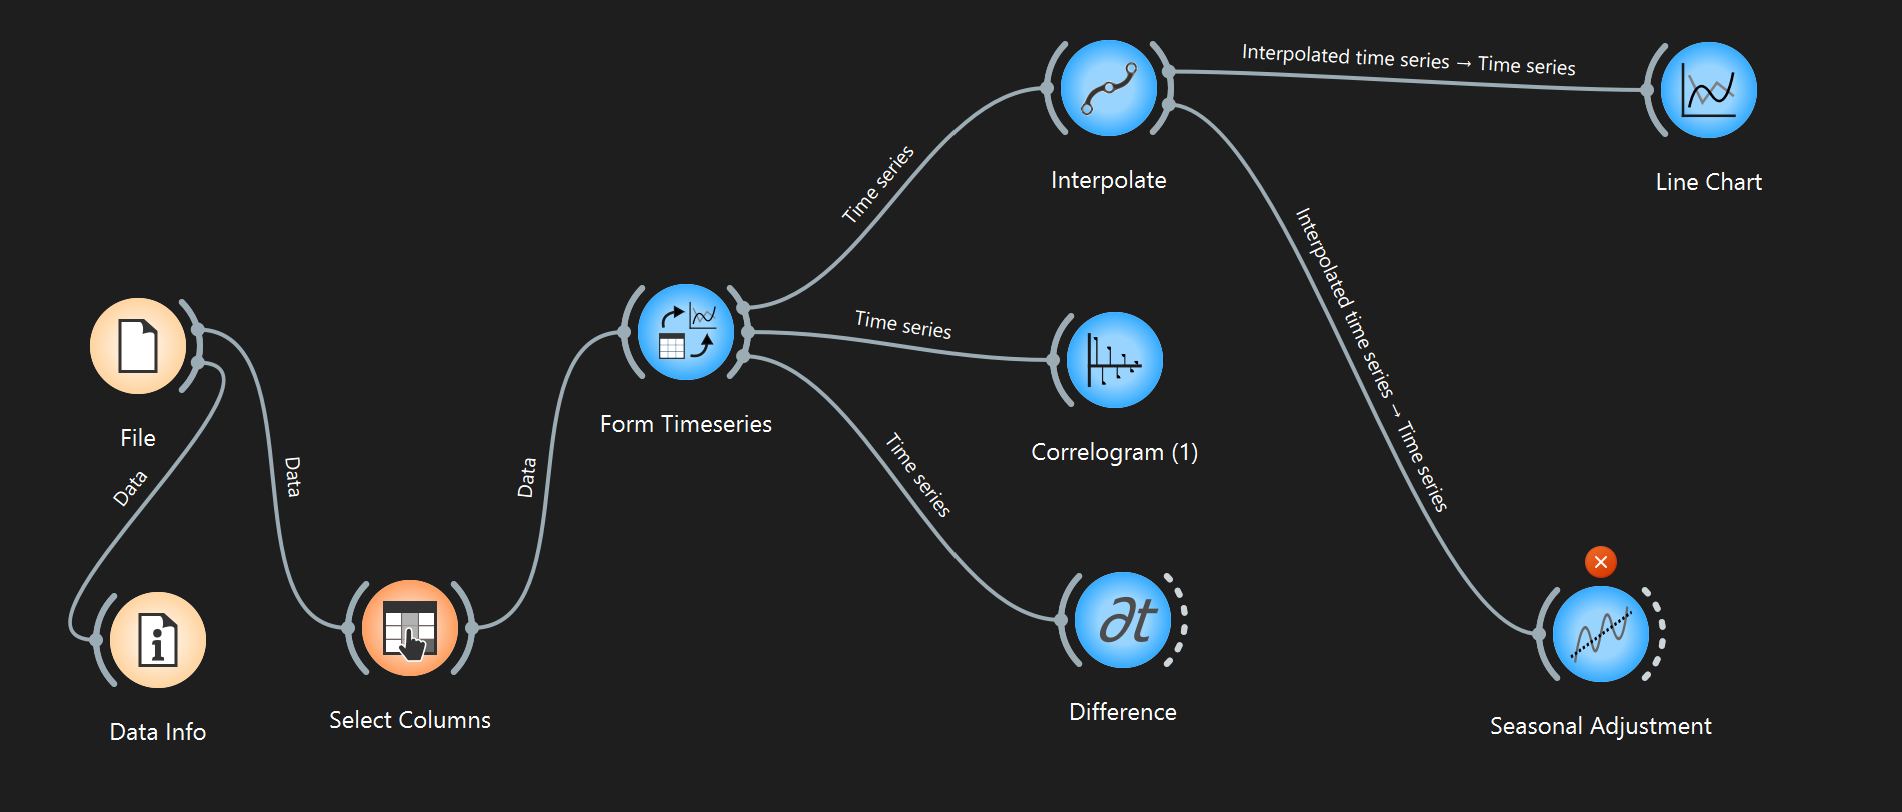

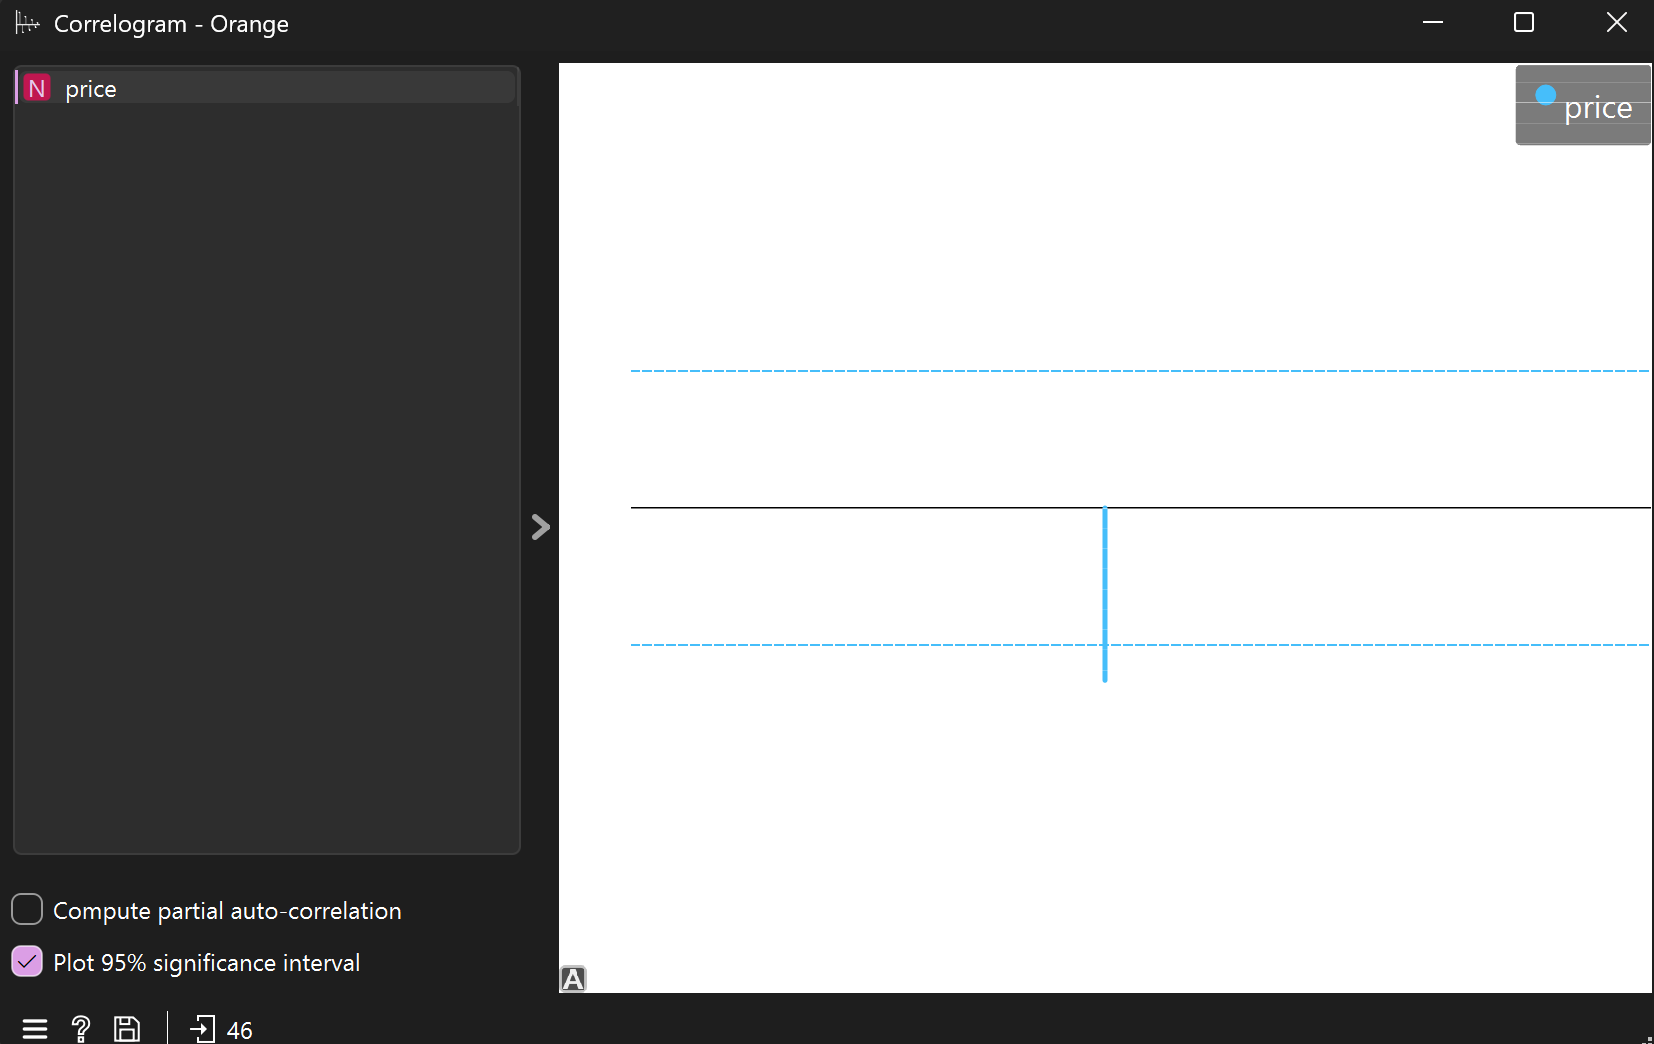

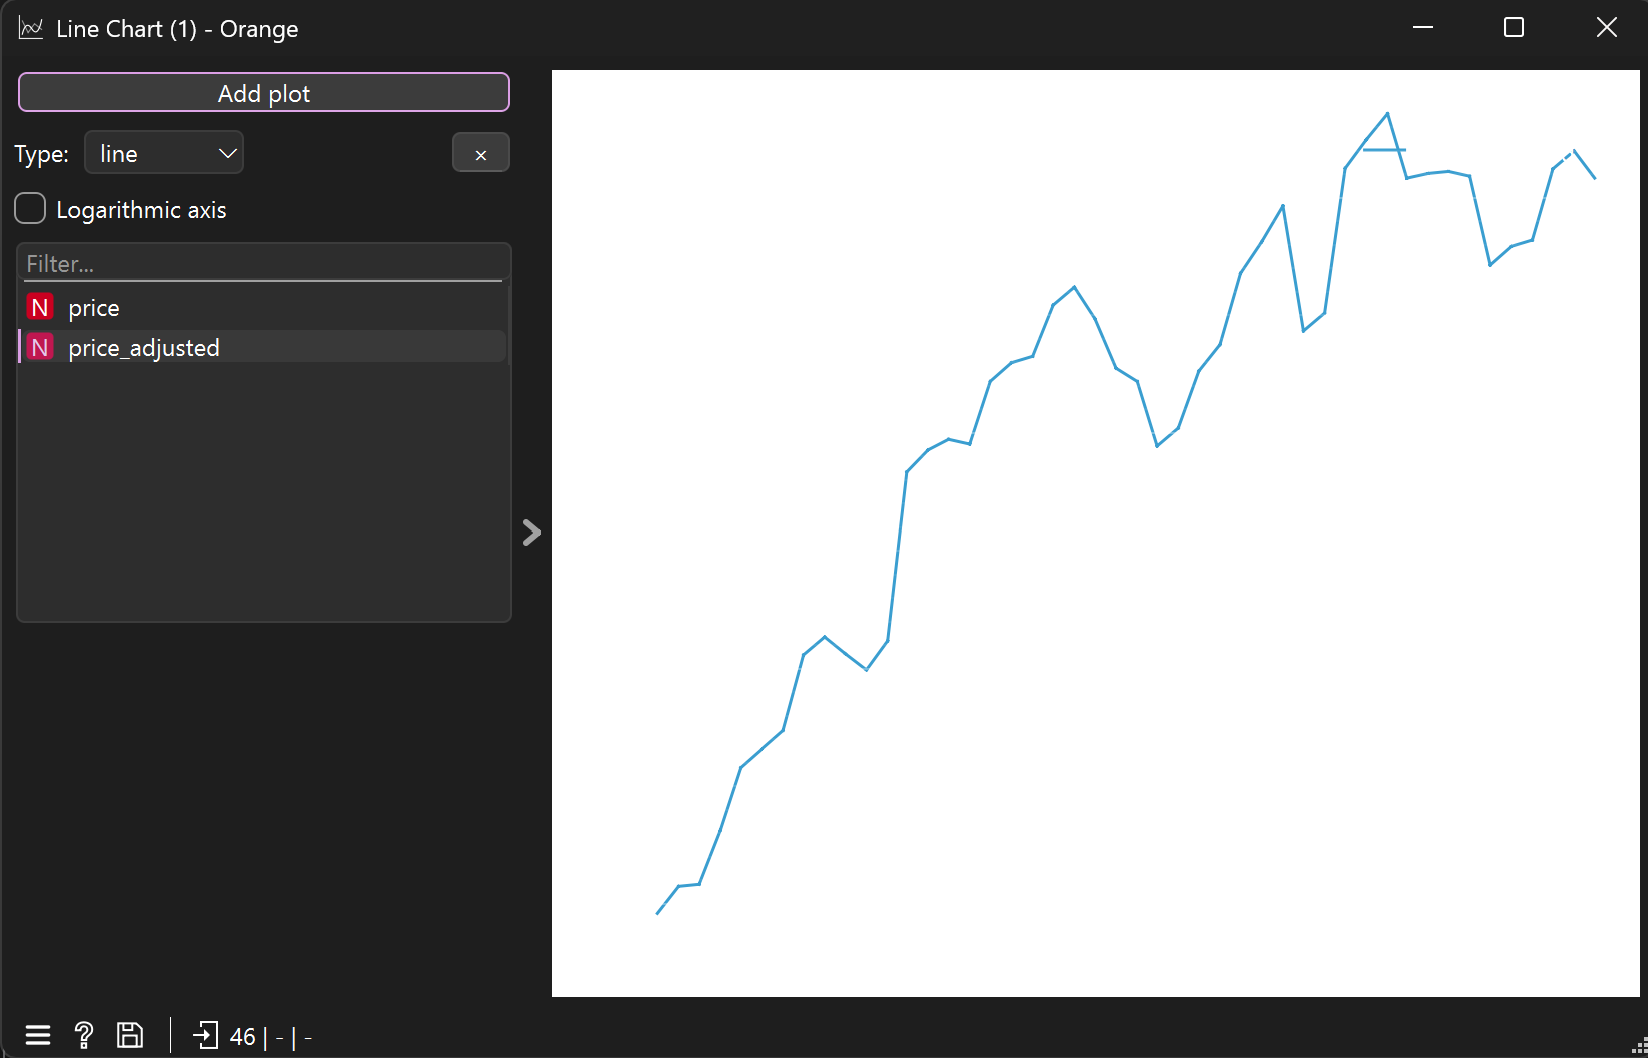

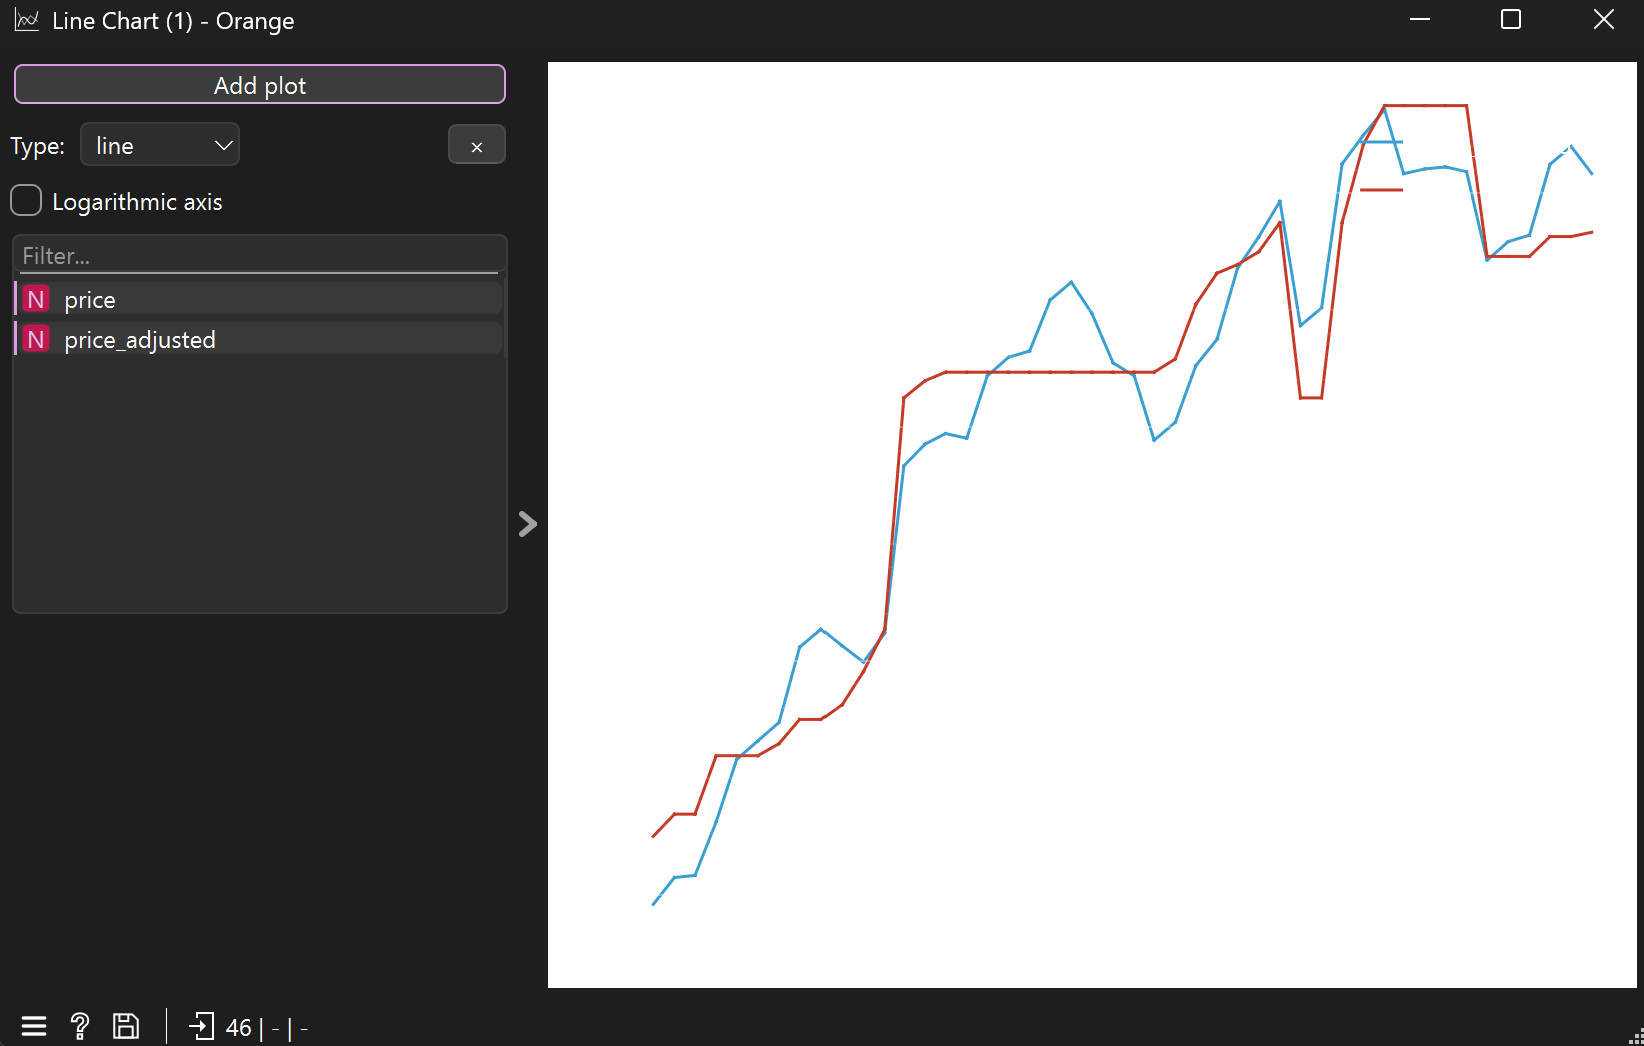


In [ ]:

import pandas as pd
from statsmodels.tsa.seasonal import seasonal_decompose

decomp = seasonal_decompose(
    s_filled,
    model="additive",
    period=12,
    extrapolate_trend="freq"
)

adjusted = s_filled - decomp.seasonal

df_adjusted = pd.DataFrame({
    "date": s_filled.index.strftime("%Y-%m-%d"),
    "price": s_filled.values,
    "price_adjusted": adjusted.values
})

df_adjusted.to_csv(
    "ряд_сезонно_скоригований.csv",
    index=False,
    encoding="utf-8"
)

print("Кількість рядків:", len(df_adjusted))
print("Пропусків:", df_adjusted.isna().sum().sum())
print(df_adjusted.head())


Кількість рядків: 46
Пропусків: 0
         date  price  price_adjusted
0  2014-03-01   4.50        3.917980
1  2014-04-01   4.69        4.148080
2  2014-05-01   4.69        4.165298
3  2014-06-01   5.19        4.624904
4  2014-07-01   5.19        5.158027


C:\Users\Соломія\AppData\Local\Temp\ipykernel_24940\1916737164.py:5: FutureWarning: `extrapolate_trend='freq'` is deprecated and will be removed in 0.16, use `extrapolate_trend='period'` instead.
  decomp = seasonal_decompose(


У завданні 12 дослідила автокореляцію та виконала перше диференціювання ряду. Після диференціювання значущої автокореляції на відображеному лагу не виявлено. Через помилку Seasonal Adjustment сезонне коригування виконала в Python, а результат візуалізувала в Orange. Порівняння зі STL показало, що обидва методи враховують сезонні коливання, хоча результати можуть відрізнятися.

## Завдання 13. Модель і оцінювання

Додайте `ARIMA Model` з порядком **(1, 1, 1)** та `Model Evaluation`.

У віджеті **Model Evaluation** встановіть **Number of folds = 7** та **Forecast steps = 3**.

**У звіті наведіть:**
1. знімок таблиці Model Evaluation з усіма метриками;
2. **що станеться, якщо лишити типові налаштування** (20 фолдів × 3 кроки) — наведіть повідомлення, яке видасть Orange, і поясніть, звідки воно береться;
3. які саме 7 фолдів перевіряє Orange — тобто на яких відрізках ряду навчається модель.

> 💡 **Підказка.** Orange відмовиться працювати при типових налаштуваннях. Це не збій, а наслідок довжини вашого ряду — порахуйте, якої саме.

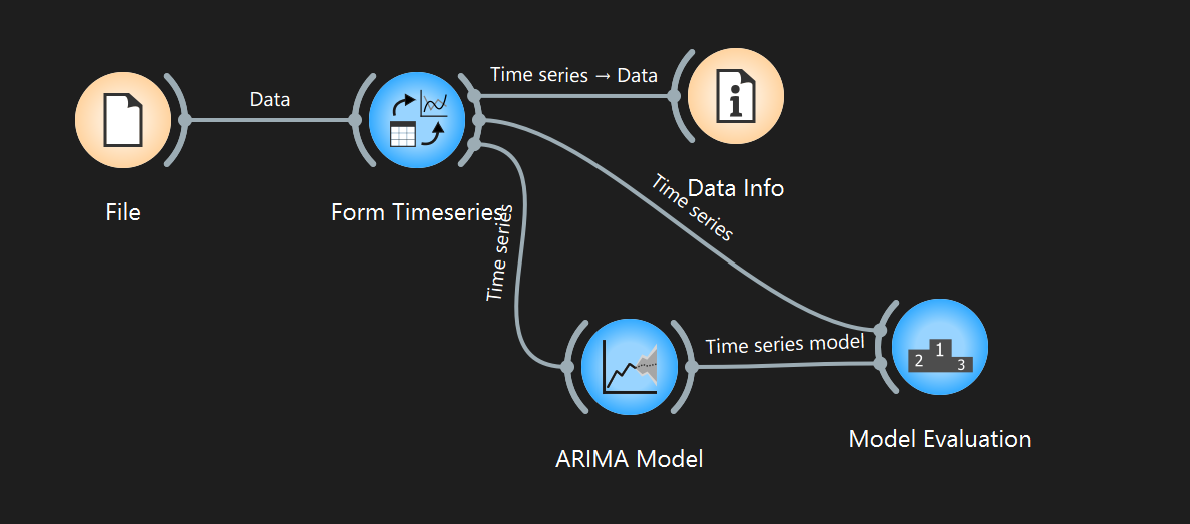

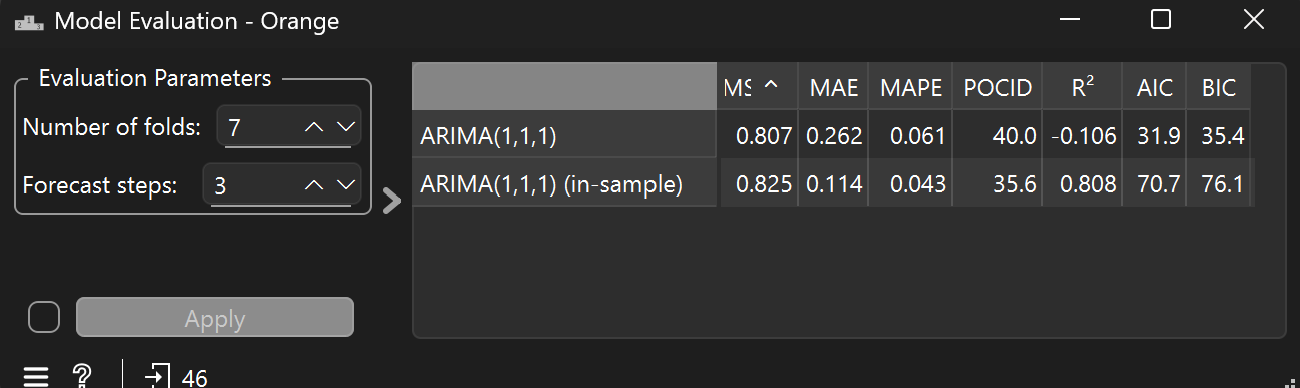

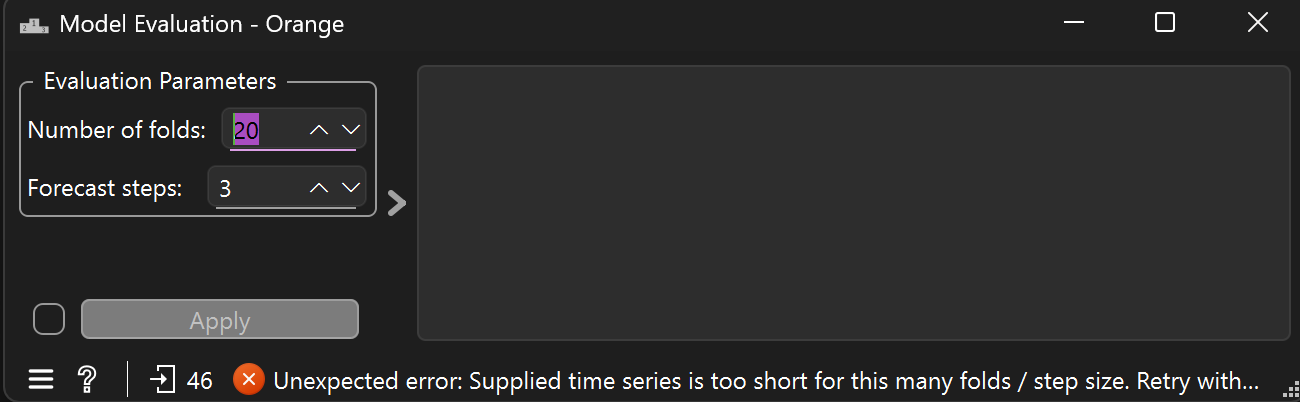


- Найраніша перевірка: навчання на 25 місяцях, прогноз на квітень–червень 2016 року.
- Найпізніша: навчання на 43 місяцях, прогноз на жовтень–грудень 2017 року.
- Загалом перевіряються 21 прогнозне значення без використання майбутніх даних під час навчання. 
  GitHub

In [24]:

print("Модель: ARIMA(1,1,1)")
print("Кількість фолдів: 7")
print("Горизонт прогнозу: 3 місяці")

print("\nРезультати Orange:")
print("RMSE = 0.807")
print("MAE = 0.262")
print("MAPE = 0.061")
print("POCID = 40.0%")
print("R² = -0.106")

print("\nПри 20 фолдах Orange видає помилку:")
print("Часовий ряд занадто короткий.")


Модель: ARIMA(1,1,1)
Кількість фолдів: 7
Горизонт прогнозу: 3 місяці

Результати Orange:
RMSE = 0.807
MAE = 0.262
MAPE = 0.061
POCID = 40.0%
R² = -0.106

При 20 фолдах Orange видає помилку:
Часовий ряд занадто короткий.


**Висновок до завдання 13:**

В Orange побудувала модель ARIMA(1,1,1) і перевірила її на 7 фолдах по 3 місяці. Отримала RMSE = 0,807, MAE = 0,262 та MAPE = 0,061. При 20 фолдах Orange видав помилку, оскільки 46 спостережень недостатньо для такого горизонту перевірки.

## Завдання 14. Чому числа не збігаються

Порівняйте метрики Orange з метриками, які ви отримали в Частині 1 для **тієї самої** моделі
ARIMA(1,1,1) на **тих самих** 7 фолдах.

Для кожної з чотирьох метрик Orange — `RMSE`, `MAE`, `MAPE`, `POCID` — **відтворіть її значення в Python**,
тобто напишіть формулу, за якою Orange отримав саме це число, і переконайтеся, що ваш розрахунок
збігається з таблицею Orange до третього знака.

**У звіті наведіть:**
1. таблицю на чотири рядки: метрика · значення Orange · ваше відтворення в Python · формула;
2. **яка з метрик не відповідає своїй назві** — і чим саме вона відрізняється від того, що зазвичай позначають цією абревіатурою;
3. яка метрика збіглася між середовищами одразу і чому;
4. висновок: що саме треба перевіряти, перш ніж порівнювати числа з двох різних інструментів.

> 💡 **Підказка.** Жодна з розбіжностей не є помилкою Orange. Усі формули відкриті — шукайте їх у вихідному коді додатка Timeseries, файл `functions.py`.

In [26]:

import numpy as np
import pandas as pd
from statsmodels.tsa.arima.model import ARIMA

y = np.asarray(s_filled.sort_index(), dtype=float)

true_all = []
pred_all = []

for fold in range(1, 8):
    train_end = -fold * 3

    train = y[:train_end]
    test = y[train_end:][:3]

    model = ARIMA(train, order=(1, 1, 1)).fit()
    pred = np.asarray(model.forecast(steps=3))

    true_all.extend(test)
    pred_all.extend(pred)

true_all = np.array(true_all)
pred_all = np.array(pred_all)

rmse = np.sqrt(np.mean((true_all - pred_all)**2))

mae = np.median(np.abs(true_all - pred_all))

mape = np.mean(np.abs(true_all - pred_all)) / np.mean(np.abs(true_all))

pocid = 100 * np.mean(
    (np.diff(true_all) * np.diff(pred_all)) > 0
)

comparison = pd.DataFrame({
    "Метрика": ["RMSE", "MAE", "MAPE", "POCID"],
    "Orange": [0.807, 0.262, 0.061, 40.0],
    "Python": [rmse, mae, mape, pocid],
    "Формула": [
        "Корінь із середньої квадратичної помилки",
        "Медіана абсолютних помилок",
        "Середня абсолютна помилка / середня абсолютна ціна",
        "Відсоток правильних напрямків зміни"
    ]
})

print("Кількість прогнозних значень:", len(pred_all))
display(comparison.round(3))


c:\Users\Соломія\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\Соломія\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


Кількість прогнозних значень: 21


,Метрика,Orange,Python,Формула
0,RMSE,0.807,0.807,Корінь із середньої квадратичної помилки
1,MAE,0.262,0.262,Медіана абсолютних помилок
2,MAPE,0.061,0.061,Середня абсолютна помилка / середня абсолютна ...
3,POCID,40.000,40.000,Відсоток правильних напрямків зміни



1. Яка метрика не відповідає своїй назві?

MAE. Зазвичай це середня абсолютна помилка (Mean Absolute Error), але в Orange Timeseries використовується медіана абсолютних помилок.

2. Чому MAPE відрізняється від стандартної?

Orange ділить середню абсолютну помилку на середнє абсолютне значення фактичних цін, тоді як стандартна MAPE усереднює відносні помилки окремих прогнозів.

3. Чому тепер усі числа збіглися?

Ми використали однакові 7 фолдів, горизонт прогнозу 3 місяці та відтворили формули Orange.


**Висновок до завдання 14:**

У завданні 14 відтворила всі чотири метрики Orange у Python. Значення збіглися до третього знака. З'ясувала, що MAE в Orange обчислюється як медіана, а MAPE має іншу формулу, ніж стандартна. Отже, перед порівнянням результатів потрібно перевіряти формули метрик і налаштування перевірки.

## Завдання 15. Матриця напрямку зміни

Метрика `POCID` у Orange вимірює, чи правильно модель передбачає **напрямок** зміни ціни.
Розгорніть її в таблицю 2×2: рядки — що сталося насправді (зросла / впала),
стовпці — що передбачила модель.

**У звіті наведіть:**
1. заповнену матрицю 2×2 для вашої моделі;
2. перевірку, що частка правильних передбачень збігається зі значенням POCID із Orange;
3. висновок: чи корисна ваша модель для рішення «купувати зараз чи чекати», і чому це **інше питання**, ніж те, на яке відповідають MAE та RMSE.

> 💡 **Підказка.** Ця матриця — часоворядовий відповідник матриці похибок із класифікації.

In [27]:

import numpy as np
import pandas as pd

actual = np.asarray(true_all)
predicted = np.asarray(pred_all)

actual_diff = np.diff(actual)
predicted_diff = np.diff(predicted)

up_up = np.sum((actual_diff > 0) & (predicted_diff > 0))
up_down = np.sum((actual_diff > 0) & (predicted_diff < 0))
down_up = np.sum((actual_diff < 0) & (predicted_diff > 0))
down_down = np.sum((actual_diff < 0) & (predicted_diff < 0))

matrix = pd.DataFrame(
    [[up_up, up_down],
     [down_up, down_down]],
    index=["Фактично зросла", "Фактично впала"],
    columns=["Прогноз зростання", "Прогноз падіння"]
)

display(matrix)

zero_changes = np.sum(
    (actual_diff == 0) | (predicted_diff == 0)
)

correct = up_up + down_down
total = len(actual_diff)
pocid = correct / total * 100

print("Правильних напрямків:", correct)
print("Усього порівнянь:", total)
print("Порівнянь із нульовою зміною:", zero_changes)
print(f"POCID Python: {pocid:.3f}%")
print("POCID Orange: 40.000%")
print("Збігаються:", np.isclose(pocid, 40.0))


,Прогноз зростання,Прогноз падіння
Фактично зросла,5,3
Фактично впала,2,3


Правильних напрямків: 8
Усього порівнянь: 20
Порівнянь із нульовою зміною: 7
POCID Python: 40.000%
POCID Orange: 40.000%
Збігаються: True


**Висновок до завдання 15:**

Побудувала матрицю напрямків зміни ціни. Модель правильно передбачила 8 із 20 напрямків, тому POCID = 40%, що збігається з Orange. Така точність недостатня для надійного рішення, купувати зараз чи чекати. MAE та RMSE оцінюють величину помилки прогнозу, а POCID — правильність напрямку зміни.

---
# Загальний висновок

Напишіть 8–12 речень, які відповідають на такі питання:

1. Чи є у вашому ряді сезонність і чим ви це довели?
2. Який метод прогнозування виявився найкращим і чи перевершив він найпростіший базис?
3. Чи знайшли ви точку зміни режиму; якщо так — чи є для неї зовнішнє пояснення?
4. Чому однаково названі метрики у двох середовищах дали різні числа?
5. Чого ви не змогли встановити через те, що ряд має лише 46 спостережень?

### Загальний висновок

**1. Чи є у вашому ряді сезонність і чим ви це довели?**

Так, сезонність присутня. За результатами STL сила сезонності Fs = 0,740, а сила тренду Ft = 0,974. Отже, сезонні коливання є, але найбільше на зміну цін впливає загальний тренд.

**2. Який метод прогнозування виявився найкращим і чи перевершив він найпростіший базис?**

Найкращим виявився наївний прогноз із MAE = 0,586. Модель ARIMA(1,1,1) отримала MAE = 0,589, тому не змогла перевершити найпростіший базовий метод.

**3. Чи знайшли ви точку зміни режиму, якщо так — чи є для неї зовнішнє пояснення?**

Так, точку зміни виявлено в березні 2015 року. Середня ціна зросла з 5,296 до 9,210 грн, і ця зміна є статистично значущою. Можливо, вона пов'язана з економічною кризою та інфляцією, але для підтвердження потрібні додаткові дані.

**4. Чому однаково названі метрики у двох середовищах дали різні числа?**

Причина в різних формулах обчислення. Зокрема, MAE в Orange розраховується як медіана абсолютних помилок, а MAPE має іншу формулу, ніж стандартна. Після відтворення формул Orange результати збіглися до третього знака.

**5. Чого ви не змогли встановити через те, що ряд має лише 46 спостережень?**

Через короткий ряд не вдалося виконати ретроспективну перевірку на 20 фолдах по 3 місяці. Також недостатньо даних для впевнених висновків про стабільність сезонності та точність довгострокових прогнозів.

---
# Критерії оцінювання

| Бали | Умова |
|---|---|
| **0** | Ряд не розкладено або прогноз не побудовано. Робота не зарахована. |
| **2** | Виконано лише Частину 1: ряд розкладено й прогноз побудовано, але в Orange аналіз не відтворено. |
| **3** | Виконано обидві частини, проте прогноз не зіставлено з наївним базисом, а розбіжність результатів двох середовищ не пояснено. |
| **4** | Ряд розкладено на складові; прогноз зіставлено з наївним базисом за ретроспективною перевіркою з рухомим початком; той самий аналіз відтворено в Orange; зіставлено результати двох середовищ і пояснено розбіжність метрик. |

**Знімаються бали за:**

* графіки без пояснення вибору геометрії та шкали;
* числа без письмового висновку;
* прогноз без порівняння з базисом;
* висновок «метрики різні, бо середовища різні» без відтворення формул;
* зошит, який не виконується від початку до кінця.

---
# Декларація про використання штучного інтелекту

Використання інструментів штучного інтелекту під час виконання цієї роботи **дозволено**.
Умова одна: ви маєте розуміти кожен рядок зданого коду й кожне написане твердження
і бути готовим пояснити їх на захисті.

Заповніть таблицю. Якщо ШІ не використовувався, напишіть «не використовувався» в першому рядку
й залиште решту порожньою.

| Питання | Ваша відповідь |
|---|---|
| Які інструменти використано (назва, версія) | Сhat GPT|
| Для яких саме завдань |Допомога у виправленні помилок Orange в завданнях 12–13|
| Що саме було згенеровано (код / текст / пояснення / виправлення помилок) |Пояснення помилок, інструкції з налаштування віджетів Orange та альтернативний Python-код для сезонного коригування.|
| Що ви змінили у згенерованому результаті й чому |Перевірила запропоновані рішення на власних даних, змінила підключення віджетів і налаштування змінних.|
| Що з отриманого ви **перевірили самостійно** і яким способом |Самостійно перевірила роботу віджетів Orange, побудовані графіки та результати ARIMA, порівнявши їх з Python.|
| Чи траплялися у відповідях ШІ помилки; якщо так — які |Так. Деякі запропоновані способи усунення помилки Seasonal Adjustment не спрацювали. Тому сезонне коригування було виконано в Python, а результат візуалізовано в Orange.|

**Підтверджую, що розумію весь зданий код і всі зроблені висновки
та можу пояснити будь-яку їх частину на захисті роботи.**

Підпис: Андрусишин  Дата: 29.10.2026